# 5. El modelo y cómo se mide

El código helper está en `modelo.py`.

El notebook no entrena nada. Lee los resultados guardados en `registro/runs.jsonl`, donde queda anotada cada corrida con sus parámetros y su resultado. Para volver a medir el modelo hay que correr `python correr.py validar`, que tarda unos 15 minutos.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")  # Los módulos están en la raíz del proyecto
warnings.filterwarnings("ignore")
%matplotlib inline

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import modelo
import pruebas

plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True})
corridas = modelo.leer()
validaciones = [r for r in corridas if r["tipo"] == "validacion"]
final = [r for r in validaciones if r.get("nota") == "modelo final: lightgbm con todas las variables"][-1]

## Qué es LightGBM

LightGBM arma muchos árboles de decisión, uno después del otro. Un árbol de decisión hace preguntas sobre el item, como si el stock inicial es 1 o si la publicación es `free`, y según las respuestas llega a una hoja con una estimación de qué tan probable es que sea usado.

El primer árbol aprende una aproximación gruesa. El segundo se entrena para corregir los errores que dejó el primero, el tercero corrige lo que quedó después de los dos, y así sigue. La predicción final es la suma de lo que dice cada árbol. Esta forma de sumar árboles que se corrigen entre sí se llama gradient boosting.

Se eligió porque funciona muy bien con tablas de variables de distintos tipos, maneja solo los valores faltantes y las variables categóricas, y en las pruebas de más abajo superó a los otros algoritmos.

## Qué recibe

El modelo recibe 183 variables por item.

- 157 no usan el target. Son datos del propio item, palabras clave y perfiles del vendedor, la categoría y las palabras del título (notebook 3).
- 26 sí usan el target y se calculan con folds para no filtrarlo, como la tasa de usados del vendedor o de los títulos más parecidos (notebook 4).

Once de las variables son categóricas, como el tipo de publicación o la provincia. LightGBM las usa directamente, sin pasarlas a números.

Para cada item el modelo da una probabilidad de que sea usado. Si pasa de 0,5 se predice `used` y si no, `new` (D52).

In [2]:
pd.Series(modelo.CATEGORICAS, name="variables categóricas").to_frame()

,variables categóricas
0,listing_type_id
1,buying_mode
2,ship_mode
3,status
4,sub_status
5,tags
6,ship_tags
7,currency_id
8,seller_state
9,attr_estado


## Los hiperparámetros

Los hiperparámetros son las opciones que se fijan antes de entrenar, como cuántos árboles armar o qué tan grandes pueden ser. Los de este modelo salieron de una búsqueda automática, que se explica más abajo.

| Hiperparámetro | Qué controla |
|---|---|
| `n_estimators` | Cuántos árboles se arman, uno detrás del otro |
| `learning_rate` | Cuánto pesa cada árbol nuevo en la suma. Con un valor bajo, cada árbol corrige un poco y hacen falta más árboles, pero el modelo generaliza mejor |
| `num_leaves` | Cuántas hojas puede tener cada árbol, o sea qué tan detalladas pueden ser sus reglas |
| `min_child_samples` | Cuántos items tiene que tener como mínimo cada hoja |
| `colsample_bytree` | Qué fracción de las variables ve cada árbol, elegidas al azar |
| `subsample` y `subsample_freq` | Qué fracción de los items ve cada árbol, elegidos al azar en cada ronda |
| `reg_lambda` y `reg_alpha` | Penalizaciones que achican los valores de las hojas, para que ningún árbol pese demasiado |

Que cada árbol vea solo una parte de las variables y de los items hace que los árboles sean distintos entre sí y que el modelo dependa menos de casos particulares de train.

In [3]:
pd.Series(modelo.PARAMETROS, name="valor").to_frame()

,valor
n_estimators,1500.000000
learning_rate,0.034310
num_leaves,149.000000
min_child_samples,5.000000
colsample_bytree,0.687459
subsample,0.834477
subsample_freq,1.000000
reg_lambda,0.078270
reg_alpha,0.029235


## Cómo se mide

Para saber qué tan bien predice el modelo hay que probarlo con items que no vio al entrenar. Kaggle no da las etiquetas del test, así que esa prueba se hace dentro de train con validación cruzada.

Train se divide al azar en 5 partes del mismo tamaño, que se llaman folds. El modelo se entrena con 4 partes (56.000 items) y se mide el accuracy en la quinta (14.000 items). Eso se repite 5 veces, cambiando la parte que queda afuera, hasta que cada item fue medido una vez.

Todo eso se hace dos veces, con dos divisiones al azar distintas (seeds 0 y 1). Así se obtienen 10 mediciones, y el resultado del modelo es su promedio.

Hay un cuidado más. Las 26 variables que usan el target se recalculan dentro de cada ronda, usando solo las etiquetas de las 4 partes de entrenamiento. Si se calcularan con todo train, la tasa de usados del vendedor ya incluiría la etiqueta del item que se está midiendo, y el accuracy saldría inflado. De esta forma, cada ronda reproduce lo que pasa al predecir el test.

Todas las corridas de tipo `validacion` usan exactamente estas mismas 10 divisiones. Eso permite comparar dos versiones del modelo fold por fold, que es más preciso que comparar solo los promedios.

## El resultado

La tabla de abajo muestra el accuracy de cada una de las 10 mediciones del modelo final.

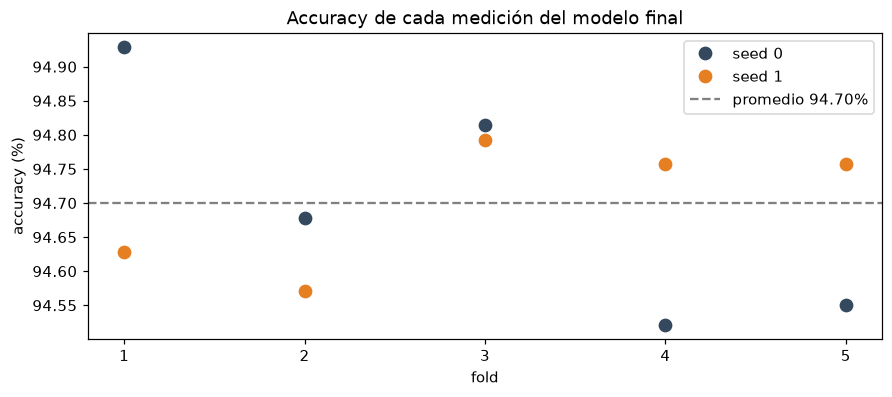

,valor
accuracy promedio,94.700%
peor medición,94.521%
mejor medición,94.929%
error estándar,0.040 puntos
predecir siempre new,"53,7%"


In [4]:
aciertos = np.array(final["accuracy_por_fold"])
por_fold = pd.DataFrame({
    "seed": np.repeat(final["protocolo"]["semillas"], final["protocolo"]["n_folds"]),
    "fold": np.tile(np.arange(1, final["protocolo"]["n_folds"] + 1), len(final["protocolo"]["semillas"])),
    "accuracy": aciertos,
})

fig, ax = plt.subplots(figsize=(8, 3.5))
for seed, color in zip(final["protocolo"]["semillas"], ["#34495e", "#e67e22"]):
    filas = por_fold[por_fold["seed"] == seed]
    ax.plot(filas["fold"], 100 * filas["accuracy"], "o", color=color, markersize=8, label=f"seed {seed}")
ax.axhline(100 * aciertos.mean(), color="grey", ls="--", label=f"promedio {100 * aciertos.mean():.2f}%")
ax.set(xlabel="fold", ylabel="accuracy (%)", xticks=range(1, 6), title="Accuracy de cada medición del modelo final")
ax.legend()
plt.show()

pd.DataFrame({"valor": {
    "accuracy promedio": f"{100 * aciertos.mean():.3f}%",
    "peor medición": f"{100 * aciertos.min():.3f}%",
    "mejor medición": f"{100 * aciertos.max():.3f}%",
    "error estándar": f"{100 * final['error_estandar']:.3f} puntos",
    "predecir siempre new": "53,7%",
}})

El modelo acierta el 94,70% de los items que no vio. Las 10 mediciones van de 94,52% a 94,93%, así que el resultado no depende de cómo cayeron los folds. El error estándar, de 0,04 puntos, indica cuánto podría moverse el promedio si se repitiera todo con otras divisiones.

Para tener una referencia, predecir siempre `new` acierta el 53,7%. El modelo comete un error cada 19 items, más o menos.

## La confirmación con folds nuevos

Las decisiones del modelo se tomaron mirando las seeds 0 y 1. Para comprobar que el resultado no está ajustado a esas divisiones en particular, el mismo modelo se midió con divisiones nuevas, que nunca se usaron para decidir nada.

In [5]:
def accuracy_de(nota):
    return [r for r in corridas if r.get("nota") == nota][-1]["accuracy"]


pd.DataFrame({"accuracy": {
    "seeds 0 y 1, las de siempre": f"{100 * final['accuracy']:.2f}%",
    "seeds 2 y 3, nuevas": f"{100 * accuracy_de('decisiones: modelo completo (semillas [2, 3])'):.2f}%",
    "seeds 4 y 5, nuevas": f"{100 * accuracy_de('simplificar: confirmacion completo'):.2f}%",
}})

,accuracy
"seeds 0 y 1, las de siempre",94.70%
"seeds 2 y 3, nuevas",94.65%
"seeds 4 y 5, nuevas",94.65%


Con las divisiones nuevas el accuracy da 94,65%, 0,05 puntos menos que con las de siempre. La diferencia es del tamaño del error estándar, así que el resultado se sostiene con datos que no participaron de ninguna decisión.

## Cómo mejoró el modelo

Cada fila de la tabla de abajo es una validación del registro en la que se agregó algo que mejoró el modelo. Todas usan las mismas divisiones, así que se pueden comparar entre sí.

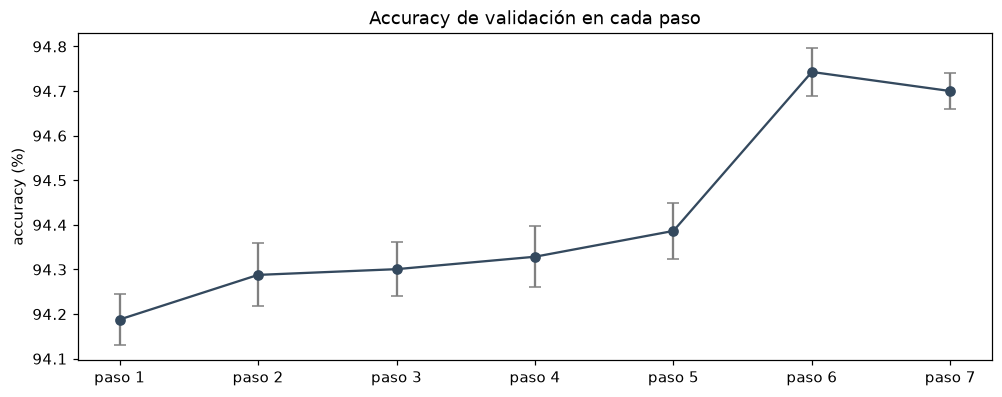

,fecha,cambio,variables,accuracy,error estándar,mejora en puntos
0,2026-10-10,LightGBM con hiperparámetros por defecto,157,94.19,0.058,NaN
1,2026-10-10,hiperparámetros buscados y vecinos por título,162,94.29,0.071,0.100
2,2026-10-11,tasas del vendedor cruzado con otras variables,172,94.30,0.061,0.013
3,2026-10-25,vecinos dentro del mismo vendedor,179,94.33,0.068,0.028
4,2026-10-25,fechas nuevas,183,94.39,0.063,0.058
5,2026-10-25,desfasaje en la duración,184,94.74,0.053,0.356
6,2026-11-04,"modelo final, sin modelo de texto y con la últ...",183,94.70,0.040,-0.043


In [6]:
HITOS = {
    "parametros por defecto": "LightGBM con hiperparámetros por defecto",
    "mejores parametros de la busqueda + vecinos por titulo": "hiperparámetros buscados y vecinos por título",
    "agrega 5 cruces de target encoding": "tasas del vendedor cruzado con otras variables",
    "cruces del vendedor y vecinos dentro del vendedor": "vecinos dentro del mismo vendedor",
    "cruces y vecinos del vendedor + fechas nuevas": "fechas nuevas",
    "agrega resto en segundos de la duracion": "desfasaje en la duración",
    "modelo final: lightgbm con todas las variables": "modelo final, sin modelo de texto y con la última limpieza",
}
pasos = pd.DataFrame([
    {"fecha": r["fecha"][:10], "cambio": etiqueta, "variables": r["features"]["n"], "accuracy": r["accuracy"],
     "error estándar": r["error_estandar"]}
    for nota, etiqueta in HITOS.items()
    for r in [next(x for x in validaciones if x["modelo"] == "lightgbm" and x.get("nota") == nota)]
])
pasos["mejora en puntos"] = (100 * pasos["accuracy"].diff()).round(3)

fig, ax = plt.subplots(figsize=(9, 3.5))
# Cada barra marca un error estándar para arriba y para abajo
ax.errorbar(range(len(pasos)), 100 * pasos["accuracy"], yerr=100 * pasos["error estándar"],
            fmt="o-", color="#34495e", ecolor="grey", capsize=4)
ax.set(xticks=range(len(pasos)), xticklabels=[f"paso {i + 1}" for i in range(len(pasos))],
       ylabel="accuracy (%)", title="Accuracy de validación en cada paso")
plt.show()
pasos.assign(accuracy=(100 * pasos["accuracy"]).round(2), **{"error estándar": (100 * pasos["error estándar"]).round(3)})

El modelo pasó de 94,19% con los hiperparámetros por defecto a 94,70%. La mayor parte de la mejora vino de una sola variable, el desfasaje de unos segundos en la duración de la publicación, que sumó 0,35 puntos (paso 6). Los demás pasos sumaron entre 0,01 y 0,10 puntos cada uno.

Las barras marcan un error estándar para arriba y para abajo, de entre 0,04 y 0,07 puntos. Los pasos 3, 4 y 5 suman menos que ese margen, así que de a uno podrían ser azar. El paso 2 lo supera apenas y el paso 6, por mucho. Comparar fold por fold, como hace el notebook 6, es más preciso que mirar si las barras se superponen.

El último paso baja 0,04 puntos porque se sacó un modelo de texto que no daba una mejora demostrable. Se prefirió un modelo más simple a cambio de esa diferencia, que no se distingue del azar (D60).

## Por qué LightGBM

Antes de elegir, se compararon varios algoritmos con las mismas variables y las mismas divisiones. La tabla de abajo los ordena por accuracy.

In [7]:
NOMBRES = {
    "lightgbm": "LightGBM", "hist_gradient_boosting": "HistGradientBoosting", "xgboost": "XGBoost",
    "catboost": "CatBoost", "random_forest": "Random Forest", "extra_trees": "Extra Trees",
    "regresion_logistica": "regresión logística", "red_neuronal": "red neuronal", "knn": "kNN",
    "clustering": "clustering",
}
de_octubre = {r["modelo"]: r for r in validaciones if r.get("nota") == "comparación de modelos sobre los mismos folds"}
de_noviembre = {r["modelo"]: r for r in validaciones if r.get("nota", "").endswith("solo, fuera del promedio")}
de_noviembre["lightgbm"] = modelo.buscar("20261102-134308-validacion-lightgbm")
comparacion = pd.DataFrame(
    [{"algoritmo": NOMBRES[m], "comparación": "octubre, 162 variables", "accuracy": round(100 * r["accuracy"], 2)}
     for m, r in de_octubre.items()]
    + [{"algoritmo": NOMBRES[m], "comparación": "noviembre, 183 variables", "accuracy": round(100 * r["accuracy"], 2)}
       for m, r in de_noviembre.items()]
)
comparacion.sort_values(["comparación", "accuracy"], ascending=[False, False]).reset_index(drop=True)

,algoritmo,comparación,accuracy
0,LightGBM,"octubre, 162 variables",94.29
1,HistGradientBoosting,"octubre, 162 variables",94.26
2,XGBoost,"octubre, 162 variables",94.25
3,CatBoost,"octubre, 162 variables",94.17
4,Extra Trees,"octubre, 162 variables",93.56
5,Random Forest,"octubre, 162 variables",93.51
6,regresión logística,"octubre, 162 variables",93.23
7,LightGBM,"noviembre, 183 variables",94.70
8,red neuronal,"noviembre, 183 variables",93.93
9,kNN,"noviembre, 183 variables",90.34


En octubre, con 162 variables, los cuatro algoritmos de gradient boosting (LightGBM, HistGradientBoosting, XGBoost y CatBoost) quedaron entre 94,17% y 94,29%, con LightGBM arriba. Random Forest, Extra Trees y la regresión logística quedaron entre 0,7 y 1,1 puntos abajo.

En noviembre, con las 183 variables actuales, se probaron una red neuronal, kNN y clustering. Ninguno se acercó a LightGBM, que dio 94,70%.

## Cómo se eligieron los hiperparámetros

Los hiperparámetros salieron de una búsqueda automática con Optuna, una librería que prueba combinaciones de valores y usa los resultados anteriores para decidir qué probar después. En lugar de recorrer una grilla fija, concentra las pruebas cerca de las combinaciones que vienen dando mejor accuracy (el método se llama TPE).

Para cada hiperparámetro se fijó un rango.

| Hiperparámetro | Rango que se probó |
|---|---|
| `n_estimators` | De 300 a 1.500, de a 100 |
| `learning_rate` | De 0,01 a 0,1 |
| `num_leaves` | De 15 a 255 |
| `min_child_samples` | De 5 a 100 |
| `colsample_bytree` | De 0,2 a 0,8 |
| `subsample` | De 0,5 a 1 |
| `reg_lambda` | De 0,01 a 30 |
| `reg_alpha` | De 0,001 a 5 |

Cada prueba se midió con un protocolo más liviano que la validación, de 4 folds y una sola seed, la 100. Además de ser más rápido, usa divisiones distintas a las de la validación, así los hiperparámetros no se eligen mirando los mismos folds con los que después se compara el modelo. Cada prueba quedó anotada en el registro como corrida de tipo `busqueda`, y la mejor de cada búsqueda se volvió a medir con la validación estándar.

Hubo dos búsquedas. La tabla de abajo resume cada una, con el id de su mejor prueba y el de la validación de esa prueba.

In [8]:
busquedas = sorted((r for r in corridas if r["tipo"] == "busqueda" and r["modelo"] == "lightgbm"),
                   key=lambda r: r["fecha"])
tandas = {
    "primera búsqueda, octubre": [r for r in busquedas if r["fecha"] < "2026-10-15"],
    "segunda búsqueda, noviembre": [r for r in busquedas if r["fecha"] >= "2026-10-15"],
}
# La mejor prueba de cada búsqueda se volvió a medir con la validación estándar
VALIDACION_DE_LA_MEJOR = {
    "primera búsqueda, octubre": "20261010-194243-validacion-lightgbm",
    "segunda búsqueda, noviembre": "20261102-144135-validacion-lightgbm",
}
resumen = {}
for nombre, tanda in tandas.items():
    mejor = max(tanda, key=lambda r: r["accuracy"])
    validada = modelo.buscar(VALIDACION_DE_LA_MEJOR[nombre])
    resumen[nombre] = {
        "pruebas": len(tanda),
        "variables": mejor["features"]["n"],
        "mejor prueba": mejor["id"],
        "accuracy de la mejor prueba, protocolo liviano": f"{100 * mejor['accuracy']:.2f}%",
        "validación estándar de esa prueba": validada["id"],
        "accuracy en la validación estándar": f"{100 * validada['accuracy']:.2f}%",
    }
pd.DataFrame(resumen)

,"primera búsqueda, octubre","segunda búsqueda, noviembre"
pruebas,17,42
variables,157,183
mejor prueba,20261010-185945-busqueda-lightgbm,20261102-143512-busqueda-lightgbm
"accuracy de la mejor prueba, protocolo liviano",94.19%,94.57%
validación estándar de esa prueba,20261010-194243-validacion-lightgbm,20261102-144135-validacion-lightgbm
accuracy en la validación estándar,94.29%,94.70%


La primera búsqueda se hizo el 10 de octubre, con las 157 variables que había en ese momento. Corrió en dos tandas, de 9 y 8 pruebas, y la segunda retomó lo aprendido en la primera. La mejor prueba fue `20261010-185945-busqueda-lightgbm`. Con la validación estándar dio 94,29% (`20261010-194243-validacion-lightgbm`), contra 94,19% de los hiperparámetros por defecto. Son los hiperparámetros que usa el modelo hoy.

El gráfico de abajo muestra el accuracy de cada prueba, en el orden en que se hicieron, y el mejor valor encontrado hasta ese momento.

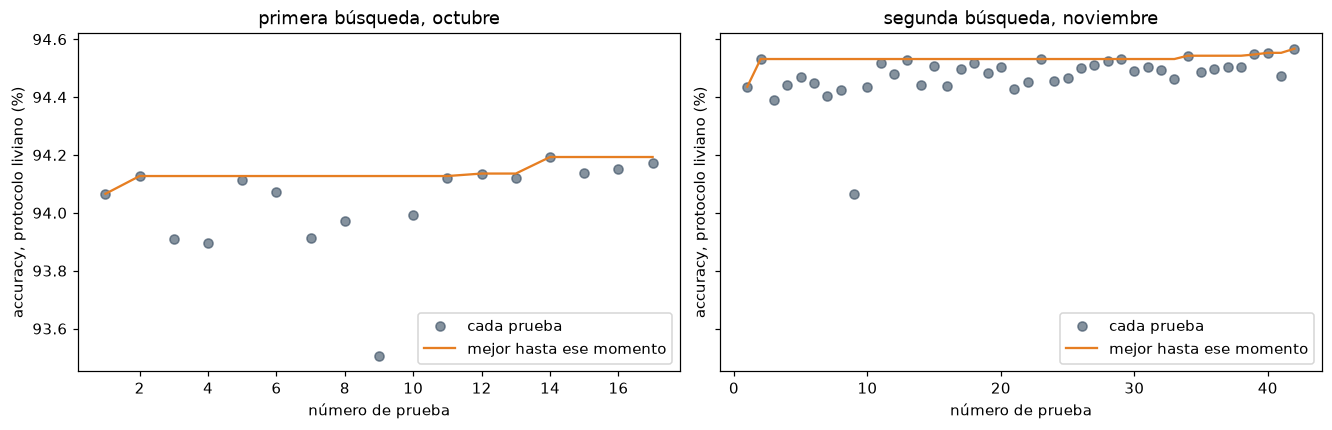

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (nombre, tanda) in zip(ejes, tandas.items()):
    accuracy = 100 * np.array([r["accuracy"] for r in tanda])
    numero = np.arange(1, len(accuracy) + 1)
    ax.plot(numero, accuracy, "o", color="#34495e", alpha=0.6, label="cada prueba")
    ax.plot(numero, np.maximum.accumulate(accuracy), color="#e67e22", label="mejor hasta ese momento")
    ax.set(title=nombre, xlabel="número de prueba", ylabel="accuracy, protocolo liviano (%)")
    ax.legend(loc="lower right")
plt.show()

# Los hiperparámetros del modelo son los de la mejor prueba de octubre
assert modelo.buscar("20261010-185945-busqueda-lightgbm")["parametros"] == modelo.PARAMETROS

En octubre, 11 de las 17 pruebas quedaron a menos de 0,2 puntos de la mejor, y en noviembre, 41 de 42. Dentro de estos rangos, el accuracy cambia poco con los hiperparámetros. Los dos gráficos comparten el eje vertical, pero sus valores no se comparan entre sí, porque cada búsqueda usó variables distintas.

La mejor prueba de octubre usó 1.500 árboles, el máximo del rango. Eso hacía pensar que quizás convenía usar todavía más. El 12 de octubre se probaron a mano variantes de esa configuración, con más árboles y un learning rate más bajo, medidas con la validación estándar. La tabla de abajo las muestra junto a la configuración de partida, `20261010-195055-validacion-lightgbm`.

In [10]:
partida = modelo.buscar("20261010-195055-validacion-lightgbm")
variantes = [r for r in validaciones if r.get("nota", "").startswith("variante de 20261010-195055")]
pd.DataFrame([
    {"corrida": r["id"], "n_estimators": r["parametros"]["n_estimators"],
     "learning_rate": round(r["parametros"]["learning_rate"], 3), "num_leaves": r["parametros"]["num_leaves"],
     "min_child_samples": r["parametros"]["min_child_samples"], "accuracy": round(100 * r["accuracy"], 3),
     "diferencia con la partida": round(100 * (r["accuracy"] - partida["accuracy"]), 3)}
    for r in [partida, *variantes]
]).set_index("corrida")

,n_estimators,learning_rate,num_leaves,min_child_samples,accuracy,diferencia con la partida
corrida,,,,,,
20261010-195055-validacion-lightgbm,1500,0.034,149,5,94.288,0.000
20261012-141255-validacion-lightgbm,1500,0.034,149,5,94.288,0.000
20261012-141938-validacion-lightgbm,3000,0.034,149,5,94.261,-0.026
20261012-142732-validacion-lightgbm,3000,0.020,149,5,94.295,0.007
20261012-143555-validacion-lightgbm,3000,0.020,149,2,94.290,0.002
20261012-144732-validacion-lightgbm,3000,0.020,255,3,94.258,-0.030
20261012-150124-validacion-lightgbm,5000,0.012,149,3,94.274,-0.014


Ninguna variante superó a la configuración de partida por más de 0,01 puntos, así que se mantuvieron los 1.500 árboles.

La segunda búsqueda se hizo el 2 de noviembre, con las 183 variables actuales, para ver si con más variables convenían otros hiperparámetros. Hizo 42 pruebas. La mejor, `20261102-143512-busqueda-lightgbm`, usa árboles más chicos (88 hojas en lugar de 149) y más regularización. Con la validación estándar dio 94,70% (`20261102-144135-validacion-lightgbm`). La tabla de abajo la compara con los hiperparámetros de octubre medidos con las mismas variables (`20261102-134308-validacion-lightgbm`).

In [11]:
de_noviembre = modelo.buscar("20261102-144135-validacion-lightgbm")
de_octubre = modelo.buscar("20261102-134308-validacion-lightgbm")
dif, error, p = pruebas.t_corregido(de_noviembre["accuracy_por_fold"], de_octubre["accuracy_por_fold"])
display(pd.DataFrame({"octubre, los del modelo": de_octubre["parametros"],
                      "noviembre": de_noviembre["parametros"]}).round(4))
pd.DataFrame({"valor": {
    "accuracy con los de octubre": f"{100 * de_octubre['accuracy']:.3f}%",
    "accuracy con los de noviembre": f"{100 * de_noviembre['accuracy']:.3f}%",
    "diferencia": f"{100 * dif:+.3f} puntos",
    "p sin ajustar": f"{p:.3f}",
}})

,"octubre, los del modelo",noviembre
n_estimators,1500.0000,1400.0000
learning_rate,0.0343,0.0342
num_leaves,149.0000,88.0000
min_child_samples,5.0000,18.0000
colsample_bytree,0.6875,0.5969
subsample,0.8345,0.9672
subsample_freq,1.0000,1.0000
reg_lambda,0.0783,0.1746
reg_alpha,0.0292,0.3094


,valor
accuracy con los de octubre,94.701%
accuracy con los de noviembre,94.703%
diferencia,+0.001 puntos
p sin ajustar,0.956


La diferencia es de 0,001 puntos, con un p de 0,956. Dos combinaciones bastante distintas dan el mismo accuracy, así que se mantuvieron los hiperparámetros de octubre (D51).

El mismo 2 de noviembre se buscaron hiperparámetros para XGBoost, HistGradientBoosting y CatBoost, con el mismo método. Se usaron en el promedio de cuatro modelos de la sección siguiente.

## Por qué un solo modelo

Promediar las predicciones de LightGBM, HistGradientBoosting, XGBoost y CatBoost dio 94,74%, 0,04 puntos más que LightGBM solo. Para saber si esa diferencia es real se usa el t pareado corregido, que compara los dos modelos fold por fold y tiene en cuenta que los folds comparten datos (se explica en el notebook 6).

In [12]:
por_id = {r["id"]: r for r in corridas}
cuatro = por_id["20261102-115951-validacion-ensamble"]["accuracy_por_fold"]
solo = por_id["20261102-134308-validacion-lightgbm"]["accuracy_por_fold"]
dif, error, p = pruebas.t_corregido(cuatro, solo)
pd.DataFrame({"valor": {
    "promedio de cuatro modelos": f"{100 * np.mean(cuatro):.2f}%",
    "LightGBM solo": f"{100 * np.mean(solo):.2f}%",
    "diferencia": f"{100 * dif:+.3f} puntos",
    "error de la diferencia": f"{100 * error:.3f} puntos",
    "p sin ajustar": f"{p:.3f}",
}})

,valor
promedio de cuatro modelos,94.74%
LightGBM solo,94.70%
diferencia,+0.038 puntos
error de la diferencia,0.024 puntos
p sin ajustar,0.149


El p da 0,149. Una diferencia de ese tamaño aparece seguido por azar, así que no hay evidencia de que el promedio sea mejor. Se eligió LightGBM solo, que es más simple de entender y de mantener (D50).

## Validación contra Kaggle

La tabla de abajo muestra, para cada submission subida a Kaggle, su accuracy de validación y su puntaje en el leaderboard público.

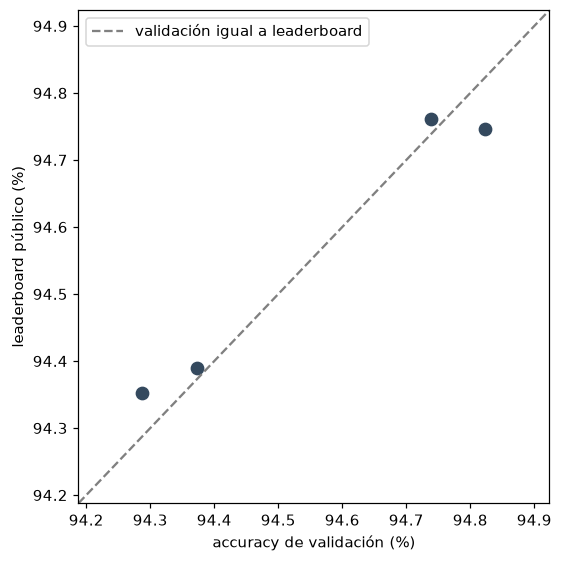

,submission,validación,leaderboard,diferencia en puntos
0,20261010-195207,94.288,94.352,-0.064
1,20261011-180636,94.374,94.390,-0.016
2,20261025-212849,94.824,94.747,0.077
3,20261102-120209,94.739,94.761,-0.022


In [13]:
puntajes = {r["submission"]: r["leaderboard_publico"] for r in corridas if r["tipo"] == "leaderboard"}
subidas = pd.DataFrame([
    {"submission": r["id"][:15], "validación": 100 * r["accuracy_validacion"], "leaderboard": 100 * puntajes[r["id"]]}
    for r in corridas if r["tipo"] == "submission" and r["id"] in puntajes
])
subidas["diferencia en puntos"] = subidas["validación"] - subidas["leaderboard"]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(subidas["validación"], subidas["leaderboard"], "o", color="#34495e", markersize=8)
limites = [subidas[["validación", "leaderboard"]].min().min() - 0.1, subidas[["validación", "leaderboard"]].max().max() + 0.1]
ax.plot(limites, limites, "--", color="grey", label="validación igual a leaderboard")
ax.set(xlim=limites, ylim=limites, xlabel="accuracy de validación (%)", ylabel="leaderboard público (%)")
ax.legend()
plt.show()
subidas.round(3)

En las cuatro submissions, la validación y el leaderboard difieren en menos de 0,08 puntos, a veces para arriba y a veces para abajo. Los puntos del gráfico quedan pegados a la línea punteada. Si el modelo estuviera sobreajustado a train, el puntaje de Kaggle quedaría sistemáticamente por debajo de la validación.

El leaderboard público mira solo una parte del test, así que también tiene su propio ruido. Por eso las decisiones se toman con la validación y no con el puntaje de Kaggle.

## Resumen

- El modelo es un LightGBM con 183 variables y acierta el 94,70% en validación cruzada.
- Con divisiones nuevas da 94,65%, y en Kaggle los puntajes coinciden con la validación.
- La mejora más grande vino de las variables, no del algoritmo. Promediar cuatro algoritmos o cambiar los hiperparámetros no dio una mejora demostrable.